In [1]:

# Importer les bibliothèques nécessaires à l'Application Agent.
# Préparer LangGraph et les outils de validation humaine.

import sys
import pydantic
import langgraph

from typing import TypedDict, Optional
from pydantic import BaseModel, Field, HttpUrl
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

print("=== Application Agent : Initialisation ===")
print("Python :", sys.version.split()[0])
print("Pydantic :", pydantic.__version__)
print("LangGraph : import réussi")
print("Human-in-the-loop : disponible")
print("Checkpointer : disponible")
print("Environnement prêt !")


=== Application Agent : Initialisation ===
Python : 3.11.17
Pydantic : 2.14.0
LangGraph : import réussi
Human-in-the-loop : disponible
Checkpointer : disponible
Environnement prêt !


In [42]:

# Définir les modèles nécessaires à la préparation des candidatures.
# Conserver les offres, les scores de matching et le statut d'envoi.

from typing import Literal
from pydantic import BaseModel, Field, HttpUrl
from typing import Optional


class JobOffer(BaseModel):
    source: str
    source_id: str
    title: str
    company: str
    location: Optional[str] = None
    description: Optional[str] = None
    tags: list[str] = Field(default_factory=list)
    job_type: Optional[str] = None
    category: Optional[str] = None
    salary: Optional[str] = None
    publication_date: Optional[str] = None
    url: HttpUrl


class MatchResult(BaseModel):
    job_id: str
    match_score: int = Field(ge=0, le=100)
    is_relevant: bool
    matching_skills: list[str] = Field(default_factory=list)
    missing_skills: list[str] = Field(default_factory=list)
    explanation: str


class JobApplication(BaseModel):
    job_id: str
    job_title: str
    company: str

    status: Literal[
        "pending",
        "skipped",
        "preparing",
        "ready",
        "submitted",
        "manual_required",
        "failed"
    ] = "pending"

    cv_path: Optional[str] = None
    cover_letter: Optional[str] = None
    cover_letter_required: Optional[bool] = None
    submission_message: Optional[str] = None
    application_url: Optional[str] = None


print("=== Application Agent : Modèles ===")
print("JobOffer : prêt")
print("MatchResult : prêt")
print("JobApplication : prêt")

print("\nStatuts possibles :")
for status in JobApplication.model_fields["status"].annotation.__args__:
    print("-", status)


=== Application Agent : Modèles ===
JobOffer : prêt
MatchResult : prêt
JobApplication : prêt

Statuts possibles :
- pending
- skipped
- preparing
- ready
- submitted
- manual_required
- failed


In [3]:

# Définir les données partagées entre les nœuds de l'Application Agent.
# Suivre chaque offre, la décision utilisateur et le statut des candidatures.

from typing import TypedDict, Optional


class ApplicationState(TypedDict):

    # Offres reçues du Matching Agent
    ranked_jobs: list[JobOffer]
    matching_results: list[MatchResult]

    # Position de l'offre actuellement présentée
    current_job_index: int

    # Décision de l'utilisateur
    user_decision: Optional[str]

    # Informations du candidat
    candidate_profile: dict
    cv_path: Optional[str]

    # Candidature en cours de préparation
    current_application: Optional[JobApplication]

    # Historique des candidatures traitées
    applications: list[JobApplication]

    # Gestion des erreurs
    errors: list[str]


print("=== ApplicationState ===")

for field_name, field_type in ApplicationState.__annotations__.items():
    print(f"{field_name} : {field_type}")

print("\nApplicationState créé avec succès !")


=== ApplicationState ===
ranked_jobs : list[__main__.JobOffer]
matching_results : list[__main__.MatchResult]
current_job_index : <class 'int'>
user_decision : typing.Optional[str]
candidate_profile : <class 'dict'>
cv_path : typing.Optional[str]
current_application : typing.Optional[__main__.JobApplication]
applications : list[__main__.JobApplication]
errors : list[str]

ApplicationState créé avec succès !


In [21]:

# Présenter une offre et son score de matching à l'utilisateur.
# Reconstruire les modèles Pydantic après restauration de l'état LangGraph.

def present_job(state: ApplicationState) -> dict:

    index = state["current_job_index"]
    jobs = state["ranked_jobs"]

    if index >= len(jobs):
        return {"user_decision": None}

    job = JobOffer.model_validate(jobs[index])

    matching_results = [
        MatchResult.model_validate(result)
        for result in state["matching_results"]
    ]

    match = next(
        (
            result for result in matching_results
            if result.job_id == job.source_id
        ),
        None
    )

    job_details = {
        "position": index + 1,
        "total": len(jobs),
        "title": job.title,
        "company": job.company,
        "location": job.location,
        "job_type": job.job_type,
        "description": job.description,
        "url": str(job.url),
        "match_score": match.match_score if match else None,
        "matching_skills": match.matching_skills if match else [],
        "missing_skills": match.missing_skills if match else [],
        "explanation": match.explanation if match else None,
        "actions": ["apply", "skip"]
    }

    decision = interrupt(job_details)

    if decision not in ("apply", "skip"):
        raise ValueError(
            "Décision invalide. Choisir 'apply' ou 'skip'."
        )

    return {"user_decision": decision}


print("Nœud present_job corrigé avec succès !")


Nœud present_job corrigé avec succès !


In [5]:

# Lire la décision de l'utilisateur après la reprise du workflow.
# Orienter LangGraph vers la préparation ou l'ignorance de l'offre.

from typing import Literal

def route_decision(
    state: ApplicationState
) -> Literal["prepare_application", "skip_job"]:

    decision = state["user_decision"]

    if decision == "apply":
        print("Décision : Postuler")
        return "prepare_application"

    if decision == "skip":
        print("Décision : Ignorer")
        return "skip_job"

    raise ValueError(
        f"Décision utilisateur non reconnue : {decision}"
    )


print("Fonction route_decision créée avec succès !")


Fonction route_decision créée avec succès !


In [25]:

# Enregistrer l'offre ignorée dans l'historique des candidatures.
# Reconstruire le modèle JobOffer et avancer vers l'offre suivante.

def skip_job(state: ApplicationState) -> dict:

    index = state["current_job_index"]

    job = JobOffer.model_validate(
        state["ranked_jobs"][index]
    )

    skipped_application = JobApplication(
        job_id=job.source_id,
        job_title=job.title,
        company=job.company,
        status="skipped"
    )

    applications = list(state.get("applications", []))
    applications.append(skipped_application.model_dump(mode="json"))

    print("\n=== OFFRE IGNORÉE ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)
    print("Statut : skipped")

    return {
        "applications": applications,
        "current_job_index": index + 1,
        "user_decision": None,
        "current_application": None
    }


print("Nœud skip_job corrigé avec succès !")


Nœud skip_job corrigé avec succès !


In [7]:

# Préparer une candidature après la décision Postuler de l'utilisateur.
# Associer le CV à l'offre et initialiser le statut de préparation.

def prepare_application(state: ApplicationState) -> dict:

    index = state["current_job_index"]
    job = state["ranked_jobs"][index]

    cv_path = state.get("cv_path")

    if not cv_path:
        error_message = (
            f"Impossible de préparer la candidature pour "
            f"{job.title} : CV introuvable."
        )

        errors = list(state.get("errors", []))
        errors.append(error_message)

        application = JobApplication(
            job_id=job.source_id,
            job_title=job.title,
            company=job.company,
            status="failed",
            submission_message=error_message
        )

        print(error_message)

        return {
            "current_application": application,
            "errors": errors
        }

    application = JobApplication(
        job_id=job.source_id,
        job_title=job.title,
        company=job.company,
        status="preparing",
        cv_path=cv_path
    )

    print("\n=== PRÉPARATION DE LA CANDIDATURE ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)
    print("CV :", cv_path)
    print("Statut :", application.status)

    return {
        "current_application": application
    }


print("Nœud prepare_application créé avec succès !")


Nœud prepare_application créé avec succès !


In [8]:

# Analyser avec le LLM si l'offre exige une lettre de motivation.
# Enregistrer la décision sans générer ni envoyer de candidature.

import os
from pathlib import Path
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field
from typing import Literal

# Charger la configuration OpenRouter
for env_path in [Path.cwd() / ".env", Path.cwd().parent / ".env"]:
    if env_path.is_file():
        load_dotenv(env_path)
        break

api_key = next(
    (
        os.getenv(f"OPENROUTER_API_KEY_{i}")
        for i in range(1, 4)
        if os.getenv(f"OPENROUTER_API_KEY_{i}")
    ),
    None
)

if not api_key:
    raise ValueError("Aucune clé OpenRouter disponible")

llm = ChatOpenAI(
    model=os.getenv("OPENROUTER_MODEL"),
    api_key=api_key,
    base_url=os.getenv(
        "OPENROUTER_BASE_URL",
        "https://openrouter.ai/api/v1"
    ),
    temperature=0
)

class CoverLetterCheck(BaseModel):
    requirement: Literal["required", "not_required", "unknown"]
    explanation: str = Field(
        description="Justification basée sur la description de l'offre"
    )

cover_letter_llm = llm.with_structured_output(
    CoverLetterCheck,
    method="function_calling"
)


def check_cover_letter(state: ApplicationState) -> dict:

    job = state["ranked_jobs"][state["current_job_index"]]
    application = state["current_application"]

    if application is None or application.status == "failed":
        return {}

    prompt = f"""
Analyse cette offre d'emploi et détermine si une lettre
de motivation est explicitement exigée.

Réponds avec :
- required : lettre obligatoire
- not_required : lettre explicitement non nécessaire
- unknown : aucune indication claire

N'invente pas d'exigences.

OFFRE :
{job.description or "Description non disponible"}
"""

    result = cover_letter_llm.invoke(prompt)

    if result is None:
        raise ValueError("Le LLM a retourné une réponse vide")

    application = application.model_copy(
        update={
            "cover_letter_required": (
                True if result.requirement == "required"
                else False if result.requirement == "not_required"
                else None
            )
        }
    )

    print("=== VÉRIFICATION LETTRE DE MOTIVATION ===")
    print("Offre :", job.title)
    print("Exigence :", result.requirement)
    print("Explication :", result.explanation)

    return {
        "current_application": application
    }


print("Nœud check_cover_letter créé avec succès !")


Nœud check_cover_letter créé avec succès !


In [9]:

# Générer une lettre de motivation personnalisée lorsque l'offre l'exige.
# Enregistrer la lettre dans la candidature sans effectuer d'envoi.

from langchain_core.messages import SystemMessage, HumanMessage

def generate_cover_letter(state: ApplicationState) -> dict:

    job = state["ranked_jobs"][state["current_job_index"]]
    application = state["current_application"]

    if application is None or application.status == "failed":
        return {}

    # Ne pas générer de lettre si elle n'est pas obligatoire
    if application.cover_letter_required is not True:
        print("Lettre non exigée : génération ignorée.")
        return {}

    candidate = state["candidate_profile"]

    system_prompt = """
Tu es un expert en rédaction de lettres de motivation.

Rédige une lettre professionnelle, personnalisée et concise
pour une candidature à une offre d'emploi.

Règles :
- Adapte la lettre au poste et à l'entreprise.
- Mets en valeur les compétences réellement présentes dans le profil.
- N'invente aucune expérience, formation ou qualification.
- N'invente pas le nom du recruteur.
- Utilise un ton professionnel et naturel.
- Rédige en français.
- Retourne uniquement le texte de la lettre.
"""

    human_prompt = f"""
PROFIL DU CANDIDAT :
{candidate}

OFFRE D'EMPLOI :
Poste : {job.title}
Entreprise : {job.company}
Description : {job.description or "Non disponible"}

Rédige une lettre de motivation adaptée à cette candidature.
"""

    response = llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=human_prompt)
    ])

    if not isinstance(response.content, str) or not response.content.strip():
        raise ValueError("Le LLM n'a pas généré de lettre valide.")

    cover_letter = response.content.strip()

    updated_application = application.model_copy(
        update={"cover_letter": cover_letter}
    )

    print("=== LETTRE DE MOTIVATION GÉNÉRÉE ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)
    print("\n", cover_letter)

    return {
        "current_application": updated_application
    }


print("Nœud generate_cover_letter créé avec succès !")


Nœud generate_cover_letter créé avec succès !


In [13]:

# Tenter une soumission automatique lorsqu'un connecteur est disponible.
# Fournir le lien de candidature manuelle si l'envoi est impossible.

from typing import Callable, Optional

# Un connecteur réel sera ajouté plus tard :
# il recevra l'offre et la candidature, puis retournera
# True uniquement si l'envoi est confirmé.
application_submitter: Optional[Callable] = None


def submit_application(state: ApplicationState) -> dict:

    application = state["current_application"]
    job = state["ranked_jobs"][state["current_job_index"]]

    if application is None:
        raise ValueError("Aucune candidature en cours.")

    if application.status != "ready":
        print("Candidature non prête : soumission impossible.")
        return {}

    print("\n=== AUTOMATIC APPLY ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)
    print("URL :", job.url)

    status = "manual_required"
    message = "Manual apply required."
    submission_confirmed = False

    # Essayer l'envoi uniquement si un connecteur réel existe
    if application_submitter is not None:

        try:
            submission_confirmed = application_submitter(
                job,
                application
            )

            if submission_confirmed is True:
                status = "submitted"
                message = "Candidature envoyée avec confirmation."

        except Exception as e:
            message = (
                f"Envoi automatique non confirmé : {e}. "
                "Manual apply required."
            )

    else:
        print("Aucun connecteur de soumission disponible.")

    # Si l'envoi n'est pas confirmé, fournir le lien manuel
    if status == "manual_required":
        message += f" Lien : {job.url}"

        print("\nManual apply required")
        print("Lien de candidature :", job.url)

    else:
        print("\nCandidature envoyée avec succès !")

    updated_application = application.model_copy(
        update={
            "status": status,
            "submission_message": message
        }
    )

    return {
        "current_application": updated_application
    }


print("Nœud submit_application mis à jour !")


Nœud submit_application mis à jour !


In [11]:

# Préparer la soumission vers le site de candidature de l'offre.
# Conserver un statut véridique tant qu'aucun envoi réel n'est confirmé.

def submit_application(state: ApplicationState) -> dict:

    application = state["current_application"]
    job = state["ranked_jobs"][state["current_job_index"]]

    if application is None:
        raise ValueError("Aucune candidature en cours.")

    if application.status != "ready":
        print("Candidature non prête : soumission impossible.")
        return {}

    print("\n=== SOUMISSION DE CANDIDATURE ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)
    print("Lien de candidature :", job.url)
    print("CV :", application.cv_path)

    if application.cover_letter:
        print("Lettre de motivation : disponible")
    else:
        print("Lettre de motivation : non fournie")

    # Aucun mécanisme d'envoi réel n'est encore connecté.
    # Ne jamais indiquer submitted sans confirmation.
    message = (
        "Dossier préparé. Soumission réelle non encore "
        "implémentée pour ce site."
    )

    updated_application = application.model_copy(
        update={
            "status": "ready",
            "submission_message": message
        }
    )

    print("Statut :", updated_application.status)
    print("Information :", message)

    return {
        "current_application": updated_application
    }


print("Nœud submit_application créé avec succès !")


Nœud submit_application créé avec succès !


In [12]:

# Enregistrer le résultat réel de la candidature dans l'historique.
# Conserver le lien manuel si nécessaire et passer à l'offre suivante.

def save_application(state: ApplicationState) -> dict:

    application = state["current_application"]
    index = state["current_job_index"]

    if application is None:
        raise ValueError("Aucune candidature à enregistrer.")

    job = state["ranked_jobs"][index]

    applications = list(state.get("applications", []))

    # Éviter les doublons dans l'historique
    applications = [
        app for app in applications
        if app.job_id != application.job_id
    ]

    applications.append(application)

    print("\n=== RÉSULTAT DE LA CANDIDATURE ===")
    print("Poste :", application.job_title)
    print("Entreprise :", application.company)
    print("Statut :", application.status)

    if application.status == "submitted":
        print("Candidature envoyée et confirmée.")

    elif application.status == "manual_required":
        print("Manual apply required.")
        print("Lien de candidature :", job.url)

    elif application.status == "failed":
        print("Erreur pendant le traitement.")

    elif application.status == "ready":
        print("Dossier prêt, mais envoi non confirmé.")

    if application.submission_message:
        print("Détails :", application.submission_message)

    next_index = index + 1

    print(f"\nProgression : {next_index}/{len(state['ranked_jobs'])}")

    if next_index < len(state["ranked_jobs"]):
        print("Passage à l'offre suivante...")
    else:
        print("Toutes les offres ont été traitées.")

    return {
        "applications": applications,
        "current_job_index": next_index,
        "current_application": None,
        "user_decision": None
    }


print("Nœud save_application créé avec succès !")


Nœud save_application créé avec succès !


In [14]:

# Vérifier s'il reste des offres à traiter après la décision utilisateur.
# Continuer vers la prochaine offre ou terminer le workflow.

def route_next_job(state: ApplicationState) -> str:

    current_index = state["current_job_index"]
    total_jobs = len(state["ranked_jobs"])

    print("\n=== VÉRIFICATION DES OFFRES ===")
    print(f"Offres traitées : {current_index}/{total_jobs}")

    if current_index < total_jobs:
        print("Prochaine étape : présenter l'offre suivante.")
        return "present_job"

    print("Toutes les offres ont été traitées.")
    print("Fin du workflow Application Agent.")

    return "end"


print("Routeur route_next_job créé avec succès !")


Routeur route_next_job créé avec succès !


In [43]:

# Construire le graphe complet de l'Application Agent avec les nœuds corrigés.
# Gérer les décisions utilisateur et les candidatures stockées au format JSON.

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


# ROUTEUR 1 : Postuler ou Ignorer
def route_decision(state: ApplicationState) -> str:

    decision = state.get("user_decision")

    if decision == "apply":
        return "prepare_application"

    if decision == "skip":
        return "skip_job"

    raise ValueError(f"Décision invalide : {decision}")


# ROUTEUR 2 : Vérifier la préparation
def route_preparation(state: ApplicationState) -> str:

    data = state.get("current_application")

    if data is None:
        raise ValueError("Aucune candidature en préparation.")

    application = JobApplication.model_validate(data)

    if application.status == "failed":
        return "save_application"

    return "check_cover_letter"


# ROUTEUR 3 : Lettre de motivation
def route_cover_letter(state: ApplicationState) -> str:

    data = state.get("current_application")

    if data is None:
        raise ValueError("Aucune candidature en cours.")

    application = JobApplication.model_validate(data)

    if application.status == "failed":
        return "save_application"

    if application.cover_letter_required is True:
        return "generate_cover_letter"

    return "prepare_documents"


# ROUTEUR 4 : Soumission
def route_submission(state: ApplicationState) -> str:

    data = state.get("current_application")

    if data is None:
        raise ValueError("Aucune candidature en cours.")

    application = JobApplication.model_validate(data)

    if application.status == "ready":
        return "submit_application"

    return "save_application"


# ROUTEUR 5 : Offre suivante ou fin
def route_next_job(state: ApplicationState) -> str:

    index = state["current_job_index"]
    total = len(state["ranked_jobs"])

    if index < total:
        print("\nPassage à l'offre suivante...")
        return "present_job"

    print("\nToutes les offres ont été traitées.")
    return "end"


# ==================================================
# CONSTRUCTION DU GRAPHE
# ==================================================

application_builder = StateGraph(ApplicationState)

# Ajouter tous les nœuds
application_builder.add_node("present_job", present_job)
application_builder.add_node("skip_job", skip_job)
application_builder.add_node("prepare_application", prepare_application)
application_builder.add_node("check_cover_letter", check_cover_letter)
application_builder.add_node("generate_cover_letter", generate_cover_letter)
application_builder.add_node("prepare_documents", prepare_documents)
application_builder.add_node("submit_application", submit_application)
application_builder.add_node("save_application", save_application)


# Point d'entrée
application_builder.add_edge(START, "present_job")


# Choix utilisateur
application_builder.add_conditional_edges(
    "present_job",
    route_decision,
    {
        "prepare_application": "prepare_application",
        "skip_job": "skip_job"
    }
)


# Préparation
application_builder.add_conditional_edges(
    "prepare_application",
    route_preparation,
    {
        "check_cover_letter": "check_cover_letter",
        "save_application": "save_application"
    }
)


# Vérification lettre de motivation
application_builder.add_conditional_edges(
    "check_cover_letter",
    route_cover_letter,
    {
        "generate_cover_letter": "generate_cover_letter",
        "prepare_documents": "prepare_documents",
        "save_application": "save_application"
    }
)


# Génération lettre -> préparation documents
application_builder.add_edge(
    "generate_cover_letter",
    "prepare_documents"
)


# Vérification avant soumission
application_builder.add_conditional_edges(
    "prepare_documents",
    route_submission,
    {
        "submit_application": "submit_application",
        "save_application": "save_application"
    }
)


# Soumission -> sauvegarde
application_builder.add_edge(
    "submit_application",
    "save_application"
)


# Offre suivante après Ignorer ou Postuler
application_builder.add_conditional_edges(
    "skip_job",
    route_next_job,
    {
        "present_job": "present_job",
        "end": END
    }
)

application_builder.add_conditional_edges(
    "save_application",
    route_next_job,
    {
        "present_job": "present_job",
        "end": END
    }
)


# ==================================================
# COMPILATION DU GRAPHE
# ==================================================

application_checkpointer = InMemorySaver(
    serde=JsonPlusSerializer(pickle_fallback=True)
)

application_graph = application_builder.compile(
    checkpointer=application_checkpointer
)

print("Application Agent compilé avec succès !")


Application Agent compilé avec succès !


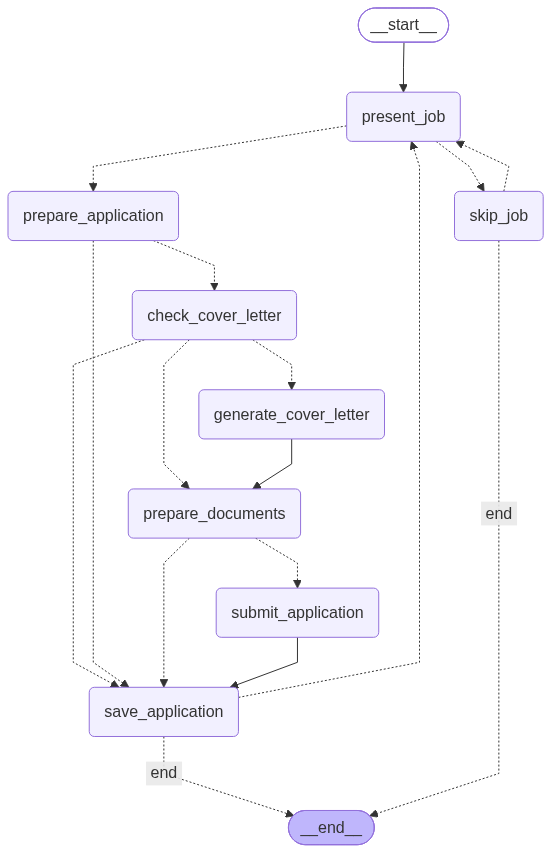

In [16]:
application_graph

In [28]:

# Tester le parcours Ignorer avec une offre fictive et une interruption utilisateur.
# Vérifier que la décision est enregistrée et que le workflow se termine.

test_job = JobOffer(
    source="remotive",
    source_id="test-job-001",
    title="Python Backend Developer",
    company="Tech Solutions",
    location="Remote",
    description="Python, FastAPI, PostgreSQL et Docker.",
    tags=["Python", "FastAPI", "Docker"],
    job_type="Full-time",
    url="https://example.com/jobs/001"
)

test_match = MatchResult(
    job_id="test-job-001",
    match_score=95,
    is_relevant=True,
    matching_skills=["Python", "FastAPI", "Docker"],
    missing_skills=["PostgreSQL"],
    explanation="Très bonne correspondance avec le profil."
)

initial_state = {
    "ranked_jobs": [test_job.model_dump(mode="json")],
    "matching_results": [test_match.model_dump(mode="json")],
    "current_job_index": 0,
    "user_decision": None,
    "candidate_profile": {},
    "cv_path": None,
    "current_application": None,
    "applications": [],
    "errors": []
}

# Identifiant unique pour cette session de test
config = {
    "configurable": {
        "thread_id": "application-test-skip-001"
    }
}

# Première exécution : l'agent attend le choix utilisateur
result = application_graph.invoke(
    initial_state,
    config=config
)

print("\n=== OFFRE PRÉSENTÉE ===")
print(result.get("__interrupt__"))

# Simuler le clic sur le bouton Ignorer
final_state = application_graph.invoke(
    Command(resume="skip"),
    config=config
)

print("\n=== RÉSULTAT FINAL ===")
print("Offres traitées :", final_state["current_job_index"])
print("Nombre de candidatures :", len(final_state["applications"]))

for application in final_state["applications"]:
    print("Poste :", application["job_title"])
    print("Statut :", application["status"])

print("Erreurs :", final_state["errors"])



=== OFFRE PRÉSENTÉE ===
[Interrupt(value={'position': 1, 'total': 1, 'title': 'Python Backend Developer', 'company': 'Tech Solutions', 'location': 'Remote', 'job_type': 'Full-time', 'description': 'Python, FastAPI, PostgreSQL et Docker.', 'url': 'https://example.com/jobs/001', 'match_score': 95, 'matching_skills': ['Python', 'FastAPI', 'Docker'], 'missing_skills': ['PostgreSQL'], 'explanation': 'Très bonne correspondance avec le profil.', 'actions': ['apply', 'skip']}, id='da12025e211c4b5e895438479bc0517a', response_schema=None)]
Décision : Ignorer

=== OFFRE IGNORÉE ===
Poste : Python Backend Developer
Entreprise : Tech Solutions
Statut : skipped

=== VÉRIFICATION DES OFFRES ===
Offres traitées : 1/1
Toutes les offres ont été traitées.
Fin du workflow Application Agent.

=== RÉSULTAT FINAL ===
Offres traitées : 1
Nombre de candidatures : 1
Poste : Python Backend Developer
Statut : skipped
Erreurs : []


In [29]:

# Préparer une candidature après le choix Postuler de l'utilisateur.
# Reconstruire l'offre Pydantic et stocker la candidature au format JSON.

def prepare_application(state: ApplicationState) -> dict:

    index = state["current_job_index"]

    job = JobOffer.model_validate(
        state["ranked_jobs"][index]
    )

    cv_path = state.get("cv_path")

    print("\n=== PRÉPARATION DE LA CANDIDATURE ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)

    if not cv_path:

        application = JobApplication(
            job_id=job.source_id,
            job_title=job.title,
            company=job.company,
            status="failed",
            submission_message="CV non fourni."
        )

        print("Erreur : aucun CV fourni.")

        return {
            "current_application": application.model_dump(mode="json"),
            "errors": state.get("errors", []) + [
                f"CV manquant pour {job.title}"
            ]
        }

    application = JobApplication(
        job_id=job.source_id,
        job_title=job.title,
        company=job.company,
        status="preparing",
        cv_path=str(cv_path)
    )

    print("CV :", cv_path)
    print("Statut :", application.status)

    return {
        "current_application": application.model_dump(mode="json")
    }


print("Nœud prepare_application corrigé avec succès !")


Nœud prepare_application corrigé avec succès !


In [30]:

# Vérifier avec le LLM si une lettre de motivation est exigée par l'offre.
# Reconstruire les modèles Pydantic et sauvegarder le résultat au format JSON.

def check_cover_letter(state: ApplicationState) -> dict:

    application_data = state.get("current_application")

    if application_data is None:
        raise ValueError("Aucune candidature en cours.")

    application = JobApplication.model_validate(application_data)

    if application.status == "failed":
        return {}

    index = state["current_job_index"]

    job = JobOffer.model_validate(
        state["ranked_jobs"][index]
    )

    print("\n=== VÉRIFICATION LETTRE DE MOTIVATION ===")
    print("Poste :", job.title)

    try:
        response = cover_letter_llm.invoke([
            (
                "system",
                "Analyse uniquement les exigences explicites "
                "de l'offre d'emploi. Détermine si une lettre "
                "de motivation est obligatoire. "
                "Réponds 'required' si elle est exigée, "
                "'not_required' si elle est explicitement facultative, "
                "et 'unknown' si ce n'est pas précisé."
            ),
            (
                "human",
                f"Titre : {job.title}\n"
                f"Entreprise : {job.company}\n"
                f"Description : {job.description or 'Non disponible'}"
            )
        ])

        if response is None:
            raise ValueError("Le LLM n'a retourné aucune réponse.")

        result = CoverLetterCheck.model_validate(response)

        requirement = result.requirement

        if requirement == "required":
            cover_letter_required = True

        elif requirement == "not_required":
            cover_letter_required = False

        else:
            cover_letter_required = None

        updated_application = application.model_copy(
            update={
                "cover_letter_required": cover_letter_required
            }
        )

        print("Exigence :", requirement)
        print("Explication :", result.explanation)

        return {
            "current_application": updated_application.model_dump(
                mode="json"
            )
        }

    except Exception as e:

        print("Erreur de vérification :", str(e))

        updated_application = application.model_copy(
            update={"cover_letter_required": None}
        )

        return {
            "current_application": updated_application.model_dump(
                mode="json"
            ),
            "errors": state.get("errors", []) + [
                f"Vérification lettre impossible pour {job.title}: {e}"
            ]
        }


print("Nœud check_cover_letter corrigé avec succès !")


Nœud check_cover_letter corrigé avec succès !


In [31]:

# Générer une lettre de motivation personnalisée uniquement si elle est exigée.
# Reconstruire les modèles Pydantic et enregistrer la lettre au format JSON.

def generate_cover_letter(state: ApplicationState) -> dict:

    application_data = state.get("current_application")

    if application_data is None:
        raise ValueError("Aucune candidature en cours.")

    application = JobApplication.model_validate(application_data)

    if application.status == "failed":
        return {}

    if application.cover_letter_required is not True:
        print("Lettre de motivation non exigée : génération ignorée.")
        return {}

    index = state["current_job_index"]

    job = JobOffer.model_validate(
        state["ranked_jobs"][index]
    )

    candidate_profile = state.get("candidate_profile", {})

    print("\n=== GÉNÉRATION LETTRE DE MOTIVATION ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)

    try:
        response = llm.invoke([
            (
                "system",
                "Tu es un assistant spécialisé dans la rédaction "
                "de lettres de motivation professionnelles. "
                "Rédige une lettre adaptée à l'offre d'emploi. "
                "Utilise uniquement les informations présentes "
                "dans le profil du candidat. "
                "N'invente aucune expérience ni compétence. "
                "Réponds uniquement avec le texte de la lettre."
            ),
            (
                "human",
                f"PROFIL DU CANDIDAT :\n{candidate_profile}\n\n"
                f"OFFRE D'EMPLOI :\n"
                f"Poste : {job.title}\n"
                f"Entreprise : {job.company}\n"
                f"Description : {job.description or 'Non disponible'}"
            )
        ])

        cover_letter = response.content

        if not isinstance(cover_letter, str) or not cover_letter.strip():
            raise ValueError("Lettre de motivation vide.")

        updated_application = application.model_copy(
            update={
                "cover_letter": cover_letter.strip()
            }
        )

        print("Lettre de motivation générée avec succès !")
        print("Nombre de caractères :", len(cover_letter.strip()))

        return {
            "current_application": updated_application.model_dump(
                mode="json"
            )
        }

    except Exception as e:

        print("Erreur de génération :", str(e))

        updated_application = application.model_copy(
            update={
                "status": "failed",
                "submission_message": (
                    "Impossible de générer la lettre obligatoire."
                )
            }
        )

        return {
            "current_application": updated_application.model_dump(
                mode="json"
            ),
            "errors": state.get("errors", []) + [
                f"Erreur lettre de motivation pour {job.title}: {e}"
            ]
        }


print("Nœud generate_cover_letter corrigé avec succès !")


Nœud generate_cover_letter corrigé avec succès !


In [32]:

from pathlib import Path

# Vérifier la présence du CV et de la lettre de motivation obligatoire.
# Empêcher toute soumission si les documents requis sont absents ou invalides.

def prepare_documents(state: ApplicationState) -> dict:

    application_data = state.get("current_application")

    if application_data is None:
        raise ValueError("Aucune candidature en cours.")

    application = JobApplication.model_validate(application_data)

    if application.status == "failed":
        print("Préparation interrompue : candidature déjà en échec.")
        return {}

    print("\n=== PRÉPARATION DES DOCUMENTS ===")
    print("Poste :", application.job_title)

    errors = list(state.get("errors", []))
    problems = []

    # Vérification du CV
    cv_path = application.cv_path

    if not cv_path:
        problems.append("CV manquant.")

    else:
        cv_file = Path(cv_path).expanduser()

        if not cv_file.is_file():
            problems.append("Fichier CV introuvable.")

        elif cv_file.suffix.lower() not in [".pdf", ".docx"]:
            problems.append("Format CV non accepté : PDF ou DOCX requis.")

        else:
            print("CV valide :", cv_file.name)

    # Vérification de la lettre de motivation
    if application.cover_letter_required is True:

        if not application.cover_letter or not application.cover_letter.strip():
            problems.append("Lettre de motivation obligatoire manquante.")

        else:
            print("Lettre de motivation : disponible")

    elif application.cover_letter_required is False:
        print("Lettre de motivation : non obligatoire")

    else:
        print("Lettre de motivation : exigence non précisée")
        print("Le connecteur devra vérifier le formulaire avant l'envoi.")

    # Déterminer le statut de préparation
    if problems:

        updated_application = application.model_copy(
            update={
                "status": "failed",
                "submission_message": " ".join(problems)
            }
        )

        errors.extend(problems)

        print("Statut : failed")
        print("Problèmes :", problems)

    else:

        updated_application = application.model_copy(
            update={"status": "ready"}
        )

        print("Statut : ready")
        print("Documents préparés avec succès !")

    return {
        "current_application": updated_application.model_dump(
            mode="json"
        ),
        "errors": errors
    }


print("Nœud prepare_documents corrigé avec succès !")


Nœud prepare_documents corrigé avec succès !


In [33]:

from typing import Callable, Optional

# Tenter l'envoi automatique uniquement lorsqu'un connecteur réel est disponible.
# Fournir un lien de candidature manuelle si aucun envoi n'est confirmé.

application_submitter: Optional[Callable] = None


def submit_application(state: ApplicationState) -> dict:

    application_data = state.get("current_application")

    if application_data is None:
        raise ValueError("Aucune candidature en cours.")

    application = JobApplication.model_validate(application_data)

    if application.status != "ready":
        print("Candidature non prête : soumission impossible.")
        return {}

    index = state["current_job_index"]

    job = JobOffer.model_validate(
        state["ranked_jobs"][index]
    )

    print("\n=== AUTOMATIC APPLY ===")
    print("Poste :", job.title)
    print("Entreprise :", job.company)
    print("Lien :", job.url)

    status = "manual_required"
    message = "Manual apply required."
    application_url = str(job.url)

    if application_submitter is not None:

        try:
            # Le connecteur devra retourner True uniquement
            # après confirmation effective de la soumission.
            confirmed = application_submitter(
                job,
                application
            )

            if confirmed is True:
                status = "submitted"
                message = "Candidature envoyée et confirmée."

        except Exception as e:
            message = (
                f"Soumission non confirmée : {e}. "
                "Vérification manuelle nécessaire."
            )

    else:
        print("Aucun connecteur automatique disponible.")

    if status == "manual_required":
        print("\nManual apply required")
        print("Lien de candidature :", application_url)
    else:
        print("\nCandidature envoyée avec confirmation !")

    updated_application = application.model_copy(
        update={
            "status": status,
            "submission_message": message
        }
    )

    # Stocker également le lien pour le frontend React.
    application_dict = updated_application.model_dump(mode="json")
    application_dict["application_url"] = application_url

    return {
        "current_application": application_dict
    }


print("Nœud submit_application corrigé avec succès !")


Nœud submit_application corrigé avec succès !


In [34]:

# Enregistrer la candidature traitée et son éventuel lien de candidature manuelle.
# Sauvegarder des dictionnaires JSON et avancer vers l'offre suivante.

def save_application(state: ApplicationState) -> dict:

    application_data = state.get("current_application")

    if application_data is None:
        raise ValueError("Aucune candidature à enregistrer.")

    application = JobApplication.model_validate(application_data)

    index = state["current_job_index"]

    job = JobOffer.model_validate(
        state["ranked_jobs"][index]
    )

    # Conserver les données JSON, y compris application_url
    application_dict = application.model_dump(mode="json")
    application_dict["application_url"] = str(job.url)

    applications = list(state.get("applications", []))

    # Éviter les doublons
    applications = [
        app for app in applications
        if JobApplication.model_validate(app).job_id != application.job_id
    ]

    applications.append(application_dict)

    print("\n=== CANDIDATURE ENREGISTRÉE ===")
    print("Poste :", application.job_title)
    print("Entreprise :", application.company)
    print("Statut :", application.status)

    if application.status == "submitted":
        print("Candidature envoyée et confirmée.")

    elif application.status == "manual_required":
        print("Manual apply required.")
        print("Lien :", application_dict["application_url"])

    elif application.status == "failed":
        print("Échec de la préparation ou du traitement.")

    elif application.status == "ready":
        print("Documents prêts, envoi non confirmé.")

    if application.submission_message:
        print("Information :", application.submission_message)

    next_index = index + 1

    print(f"\nProgression : {next_index}/{len(state['ranked_jobs'])}")

    return {
        "applications": applications,
        "current_job_index": next_index,
        "current_application": None,
        "user_decision": None
    }


print("Nœud save_application corrigé avec succès !")


Nœud save_application corrigé avec succès !


In [44]:

# Tester le parcours Postuler avec un CV local et sans connecteur automatique.
# Vérifier le fallback manual_required et l'enregistrement de la candidature.

from pathlib import Path
from langgraph.types import Command

# Recompiler le graphe après les corrections des nœuds
application_graph = application_builder.compile(
    checkpointer=InMemorySaver(
        serde=JsonPlusSerializer(pickle_fallback=True)
    )
)

# Indiquer le chemin réel de ton CV (PDF ou DOCX)
cv_test_path = Path(
    r"C:\Users\moham\Desktop\PFA IGL4\S1\Python\data\cvs\MyCv.pdf"
)

if not cv_test_path.is_file():
    raise FileNotFoundError(
        f"CV introuvable : {cv_test_path}\n"
        "Remplace cv_test_path par le chemin réel de ton CV."
    )

test_job_apply = JobOffer(
    source="remotive",
    source_id="test-apply-001",
    title="Python Backend Developer",
    company="Tech Solutions",
    location="Remote",
    description=(
        "Nous recherchons un développeur Python maîtrisant "
        "FastAPI, PostgreSQL et Docker."
    ),
    tags=["Python", "FastAPI", "Docker"],
    job_type="Full-time",
    url="https://example.com/jobs/001"
)

test_match_apply = MatchResult(
    job_id="test-apply-001",
    match_score=95,
    is_relevant=True,
    matching_skills=["Python", "FastAPI", "Docker"],
    missing_skills=["PostgreSQL"],
    explanation="Très bonne correspondance avec le profil."
)

initial_state_apply = {
    "ranked_jobs": [test_job_apply.model_dump(mode="json")],
    "matching_results": [test_match_apply.model_dump(mode="json")],
    "current_job_index": 0,
    "user_decision": None,
    "candidate_profile": {
        "full_name": "Test Candidate",
        "skills": ["Python", "FastAPI", "Docker"],
        "target_roles": ["Python Backend Developer"]
    },
    "cv_path": str(cv_test_path),
    "current_application": None,
    "applications": [],
    "errors": []
}

config_apply = {
    "configurable": {
        "thread_id": "application-test-apply-003"
    }
}

# Présenter l'offre et attendre la décision
result = application_graph.invoke(
    initial_state_apply,
    config=config_apply
)

print("\n=== OFFRE PRÉSENTÉE ===")
print(result.get("__interrupt__"))

# Simuler le clic sur Postuler
print("\nDécision : Postuler")

final_state_apply = application_graph.invoke(
    Command(resume="apply"),
    config=config_apply
)

print("\n=== RÉSULTAT FINAL ===")
print("Offres traitées :", final_state_apply["current_job_index"])
print("Nombre de candidatures :", len(final_state_apply["applications"]))

for application in final_state_apply["applications"]:
    print("Poste :", application["job_title"])
    print("Statut :", application["status"])
    print("Lien :", application.get("application_url"))

print("Erreurs :", final_state_apply["errors"])



=== OFFRE PRÉSENTÉE ===
[Interrupt(value={'position': 1, 'total': 1, 'title': 'Python Backend Developer', 'company': 'Tech Solutions', 'location': 'Remote', 'job_type': 'Full-time', 'description': 'Nous recherchons un développeur Python maîtrisant FastAPI, PostgreSQL et Docker.', 'url': 'https://example.com/jobs/001', 'match_score': 95, 'matching_skills': ['Python', 'FastAPI', 'Docker'], 'missing_skills': ['PostgreSQL'], 'explanation': 'Très bonne correspondance avec le profil.', 'actions': ['apply', 'skip']}, id='c37510f36b6046967faf626d596bfdfd', response_schema=None)]

Décision : Postuler

=== PRÉPARATION DE LA CANDIDATURE ===
Poste : Python Backend Developer
Entreprise : Tech Solutions
CV : C:\Users\moham\Desktop\PFA IGL4\S1\Python\data\cvs\MyCv.pdf
Statut : preparing

=== VÉRIFICATION LETTRE DE MOTIVATION ===
Poste : Python Backend Developer
Exigence : unknown
Explication : La description de l'offre d'emploi ne mentionne pas de exigence concernant une lettre de motivation ; seule

In [39]:

# Reconstruire le graphe avec les dernières versions corrigées des nœuds.
# Vérifier que les fonctions enregistrées sont celles actuellement définies.

import inspect

print("Version actuelle de prepare_application :")
print(
    "model_validate" in inspect.getsource(prepare_application)
)

# Réexécuter entièrement la cellule 14
# après avoir vérifié que le résultat ci-dessus est True.


Version actuelle de prepare_application :
True
